<h3>Graph IV</h3>
<h3>Conditional Graph</h3>

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    finalNumber: int

In [3]:
def adder(state: AgentState)-> AgentState: 
    """"This is adds the 2 numbers"""

    state['finalNumber'] = state['number1'] + state['number2']
    return state 

def subtractor(state: AgentState) -> AgentState: 
    """This is subtractors the 2 numbers"""
    state['finalNumber'] = state['number1'] - state['number2']
    return state 


def decide_next_node(state: AgentState)-> AgentState: 
    """This node will select the next node of the graph"""
    
    if state["operation"] == "+": 
        return "addition_operation"
    elif state["operation"] == "-":
        return "subtraction_operation"

In [4]:
graph = StateGraph(AgentState)

graph.add_node("add_node", adder)
graph.add_node("subtract_node", subtractor)
graph.add_node("router", lambda state:state) # passthrough function

graph.add_edge(START,'router')
graph.add_conditional_edges(
    "router",
    decide_next_node,
    {
        # Edge: Node
        "addition_operation": "add_node",
        "subtraction_operation": "subtract_node"
    }
)

graph.add_edge("add_node", END)
graph.add_edge("subtract_node", END)

app = graph.compile()

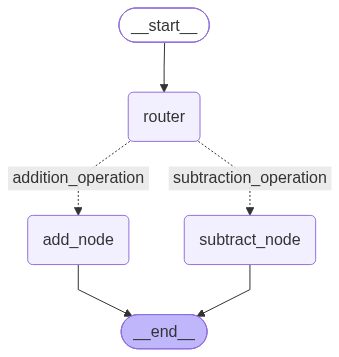

In [5]:
from IPython.display import display, Image

display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
initial_state_1 = AgentState(number1=10, operation="-", number2=5)
initial_state_2 = AgentState(number1=10, operation="+", number2=5)
print(app.invoke(initial_state_1))
print(app.invoke(initial_state_2))

{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5}
{'number1': 10, 'operation': '+', 'number2': 5, 'finalNumber': 15}


In [7]:
initial_state_3 = AgentState(number1=10, operation="*", number2=5)
print(app.invoke(initial_state_3))

KeyError: None

<h2>Error handling</h2>

In [17]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    finalNumber: int
    error: bool
    messagge: str

In [18]:
def adder(state: AgentState)-> AgentState: 
    """"This is adds the 2 numbers"""

    state['finalNumber'] = state['number1'] + state['number2']
    return state 

def subtractor(state: AgentState) -> AgentState: 
    """This is subtractors the 2 numbers"""
    state['finalNumber'] = state['number1'] - state['number2']
    return state 

def error(state: AgentState) -> AgentState: 
    """This is error node, it means if operation not equales '+' or '-'"""
    if state['operation'] not in ['+', '-']: 
        state['error'] = True
        state['messagge'] = "This operation not existing, please geving '+' or '-'"
    return state
    
def end(state: AgentState)-> AgentState: 
    """"This is a node used for direct termination."""
    return state

def decide_next_node(state: AgentState)-> AgentState: 
    """This node will select the next node of the graph"""
    if state['error'] : 
        return "end"
    if state["operation"] == "+": 
        return "addition_operation"
    
    return "subtraction_operation"

In [19]:

graph = StateGraph(AgentState)

graph.add_node("error_node", error)
graph.add_node("add_node", adder)
graph.add_node("subtract_node", subtractor)
graph.add_node("end_node", end)
graph.add_node("router", lambda state:state) # passthrough function

graph.add_edge(START, 'error_node')
graph.add_edge("error_node", "router")
graph.add_conditional_edges(
    "router",
    decide_next_node,
    {
        # Edge: Node
        "end": "end_node",
        "addition_operation": "add_node",
        "subtraction_operation": "subtract_node"
    }
)


graph.add_edge("add_node", END)
graph.add_edge("subtract_node", END)
graph.add_edge("end_node", END)

app = graph.compile()

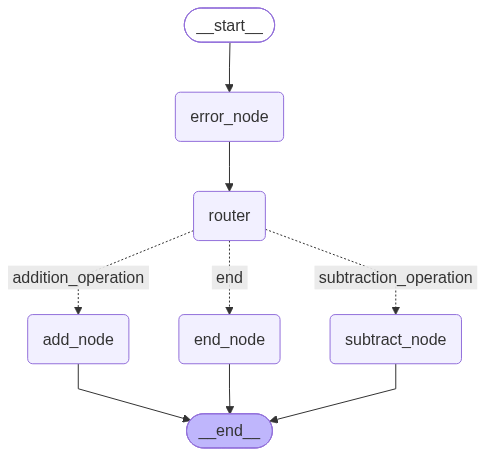

In [20]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [21]:
initial_state_1 = AgentState(number1=10, operation="-", number2=5, error=False)
initial_state_2 = AgentState(number1=10, operation="+", number2=5, error=False)
initial_state_3 = AgentState(number1=10, operation="*", number2=5, error=False)
print(app.invoke(initial_state_1))
print(app.invoke(initial_state_2))
print(app.invoke(initial_state_3))

{'number1': 10, 'operation': '-', 'number2': 5, 'finalNumber': 5, 'error': False}
{'number1': 10, 'operation': '+', 'number2': 5, 'finalNumber': 15, 'error': False}
{'number1': 10, 'operation': '*', 'number2': 5, 'error': True, 'messagge': "This operation not existing, please geving '+' or '-'"}
